# Book Data: Visualization and Storytelling

Turning data from 1,000 books (scraped from books.toscrape.com) into clear charts that show what the data says.

## The Story
What does the book market on this site look like? Is a book's price or rating connected to anything else?

Charts planned:
1. How prices are distributed
2. How ratings are distributed
3. Which categories have the most books
4. Average price by category
5. Price vs rating
6. A final summary dashboard

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("books_data.csv")

df["Price"] = df["Price"].str.replace("£", "", regex=False).astype(float)

rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
df["Rating_Num"] = df["Rating"].map(rating_map)

print(df.shape)
df.head()

(1000, 7)


,Title,Price,Rating,Stock,Link,Category,Rating_Num
0,A Light in the Attic,51.77,Three,In stock,a-light-in-the-attic_1000/index.html,Poetry,3
1,Tipping the Velvet,53.74,One,In stock,tipping-the-velvet_999/index.html,Historical Fiction,1
2,Soumission,50.10,One,In stock,soumission_998/index.html,Fiction,1
3,Sharp Objects,47.82,Four,In stock,sharp-objects_997/index.html,Mystery,4
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...,History,5


In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

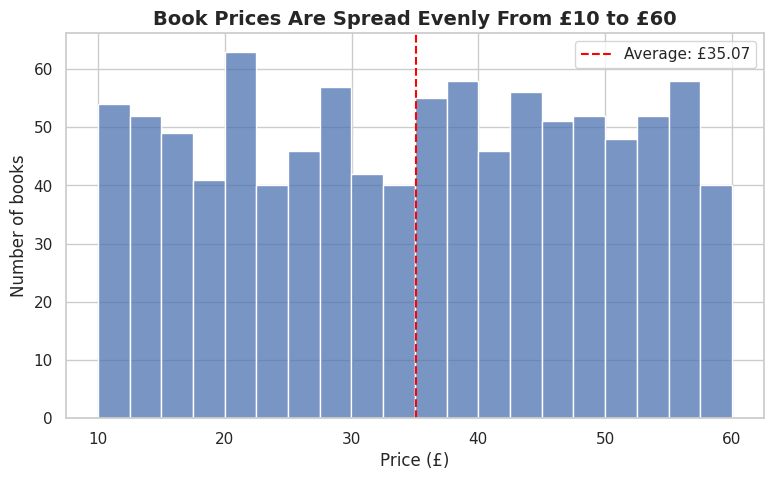

In [3]:
sns.histplot(df["Price"], bins=20, color="#4C72B0", edgecolor="white")

avg = df["Price"].mean()
plt.axvline(avg, color="red", linestyle="--", label=f"Average: £{avg:.2f}")

plt.title("Book Prices Are Spread Evenly From £10 to £60")
plt.xlabel("Price (£)")
plt.ylabel("Number of books")
plt.legend()
plt.show()

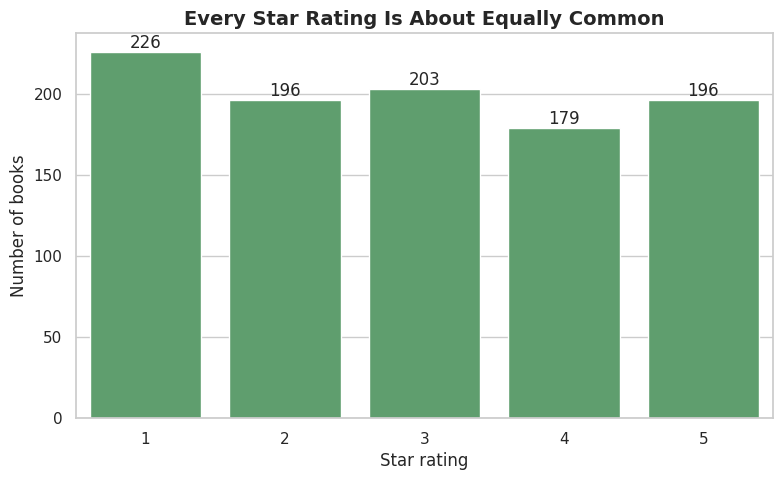

In [4]:
counts = df["Rating_Num"].value_counts().sort_index()

ax = sns.barplot(x=counts.index, y=counts.values, color="#55A868")
ax.bar_label(ax.containers[0])

plt.title("Every Star Rating Is About Equally Common")
plt.xlabel("Star rating")
plt.ylabel("Number of books")
plt.show()

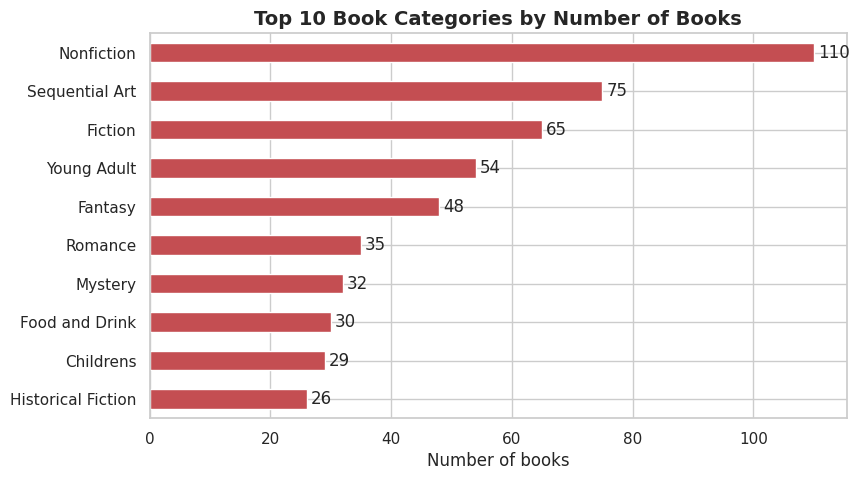

In [5]:
real = df[~df["Category"].isin(["Default", "Add a comment"])]
top_cats = real["Category"].value_counts().head(10).sort_values()

ax = top_cats.plot(kind="barh", color="#C44E52")
ax.bar_label(ax.containers[0], padding=3)

plt.title("Top 10 Book Categories by Number of Books")
plt.xlabel("Number of books")
plt.ylabel("")
plt.show()

**Note:** The placeholder categories "Default" and "Add a comment" were excluded because they are not real genres.

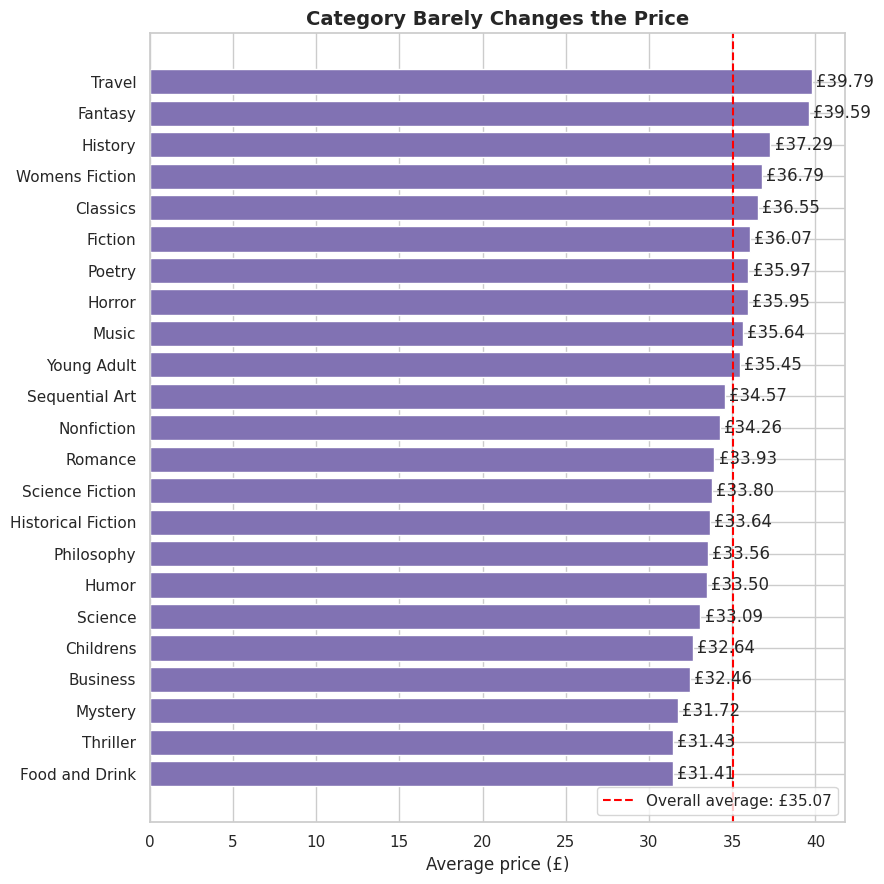

In [6]:
cat_stats = real.groupby("Category")["Price"].agg(["count", "mean"])
cat_stats = cat_stats[cat_stats["count"] >= 10].sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 9))
bars = ax.barh(cat_stats.index, cat_stats["mean"], color="#8172B3")
ax.bar_label(bars, fmt="£%.2f", padding=3)

overall = df["Price"].mean()
ax.axvline(overall, color="red", linestyle="--", label=f"Overall average: £{overall:.2f}")

ax.set_title("Category Barely Changes the Price")
ax.set_xlabel("Average price (£)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

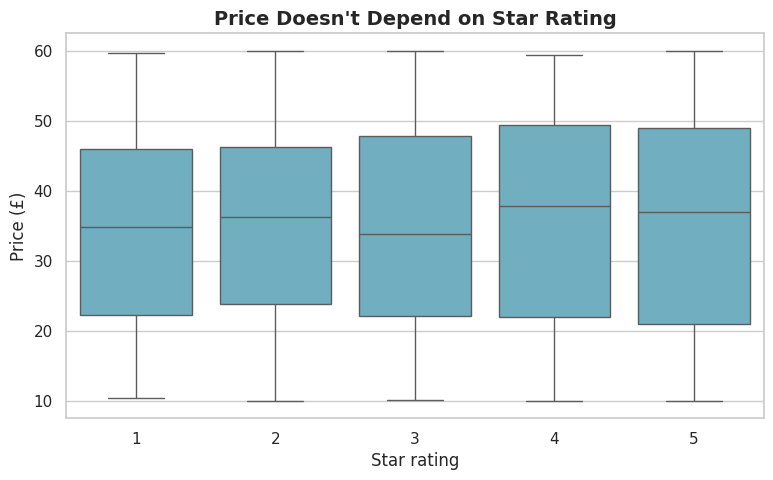

In [7]:
sns.boxplot(data=df, x="Rating_Num", y="Price", color="#64B5CD")

plt.title("Price Doesn't Depend on Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Price (£)")
plt.show()

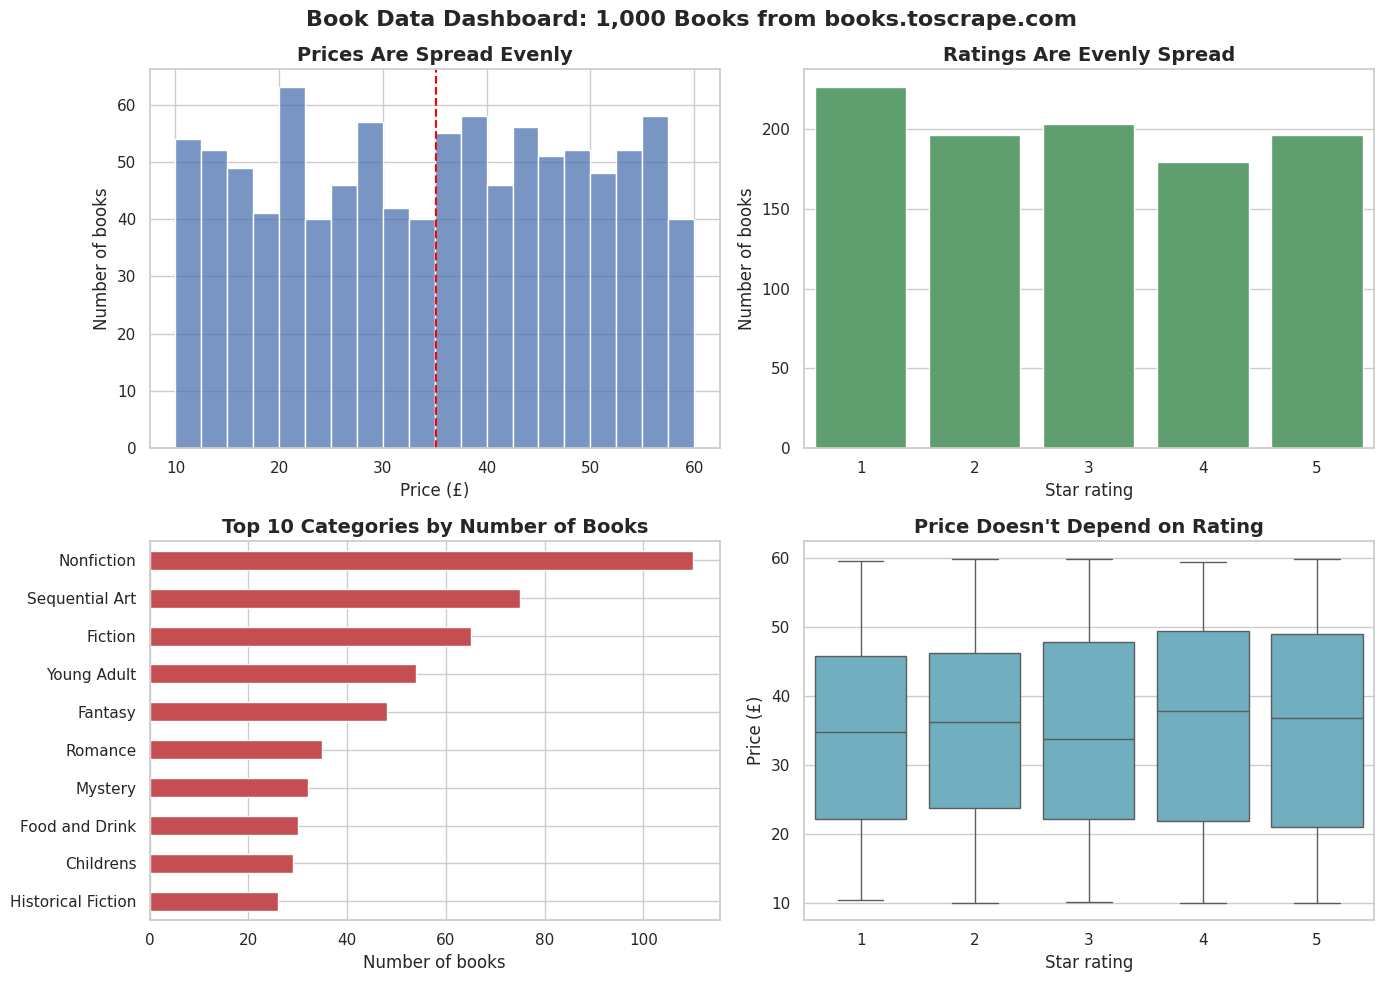

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Book Data Dashboard: 1,000 Books from books.toscrape.com", fontsize=16, fontweight="bold")

# Top left: price distribution
sns.histplot(df["Price"], bins=20, color="#4C72B0", edgecolor="white", ax=axes[0, 0])
axes[0, 0].axvline(df["Price"].mean(), color="red", linestyle="--")
axes[0, 0].set_title("Prices Are Spread Evenly")
axes[0, 0].set_xlabel("Price (£)")
axes[0, 0].set_ylabel("Number of books")

# Top right: rating distribution
sns.barplot(x=counts.index, y=counts.values, color="#55A868", ax=axes[0, 1])
axes[0, 1].set_title("Ratings Are Evenly Spread")
axes[0, 1].set_xlabel("Star rating")
axes[0, 1].set_ylabel("Number of books")

# Bottom left: top categories
top_cats.plot(kind="barh", color="#C44E52", ax=axes[1, 0])
axes[1, 0].set_title("Top 10 Categories by Number of Books")
axes[1, 0].set_xlabel("Number of books")
axes[1, 0].set_ylabel("")

# Bottom right: price vs rating
sns.boxplot(data=df, x="Rating_Num", y="Price", color="#64B5CD", ax=axes[1, 1])
axes[1, 1].set_title("Price Doesn't Depend on Rating")
axes[1, 1].set_xlabel("Star rating")
axes[1, 1].set_ylabel("Price (£)")

plt.tight_layout()
plt.savefig("dashboard.png", dpi=150)
plt.show()

## Key Takeaways

1. **Prices and ratings are evenly spread.** Prices run from £10 to £60 and ratings from 1 to 5 stars, with no strong peaks.
2. **Nonfiction is the biggest category** with 110 books, followed by Sequential Art (75) and Fiction (65).
3. **Category barely affects price.** Average prices differ by only about £8 between categories.
4. **Price and rating are unrelated.** Expensive books are not rated higher or lower than cheap ones.

## Conclusion
The even spread of prices and ratings suggests this practice website uses randomly generated values. The only real structure in the data is the number of books in each category.